# Waste classification: SVM and SVM + PCA
Run the cells from top to bottom beside `dataset-original`.

Compare **SVM** and **SVM + PCA**, both using raw resized **color pixels**. Each pixel keeps its red, green and blue channel values. We do not calculate color histograms or channel summary statistics.

Tune on training data and reserve 20% of the images for final evaluation. Training uses CPU and no pipelines. If needed, run `%pip install -r requirements.txt` in a new cell and restart the kernel.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_curve, auc

DATA_DIR = Path("dataset-original")
OUTPUT_DIR = Path("svm_results")
OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 42

## 1. Read the dataset
Labels come from the six class folders. Non-image files are ignored. The local images are high-resolution originals, so we resize them for modeling without modifying the source files.

Total images: 2527


,Images
Class,
cardboard,403
glass,501
metal,410
paper,594
plastic,482
trash,137


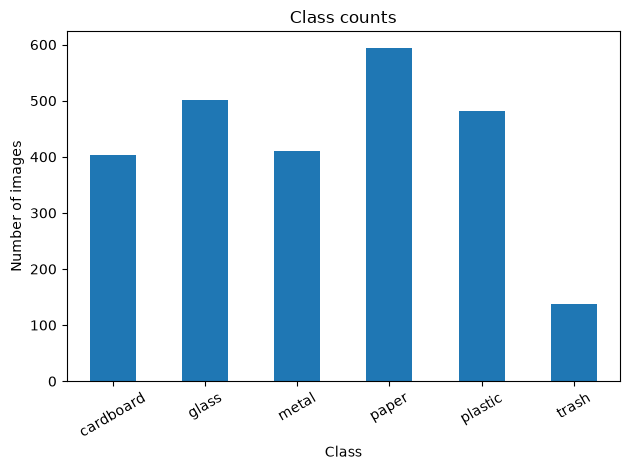

In [2]:
class_names = sorted(folder.name for folder in DATA_DIR.iterdir() if folder.is_dir())
records = []
for label, name in enumerate(class_names):
    for path in sorted((DATA_DIR / name).iterdir()):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            records.append([str(path), label, name])

images = pd.DataFrame(records, columns=["Path", "Label", "Class"])
y = images["Label"].to_numpy()
print("Total images:", len(images))
display(images["Class"].value_counts().reindex(class_names).to_frame("Images"))
images["Class"].value_counts().reindex(class_names).plot(kind="bar", rot=30)
plt.ylabel("Number of images")
plt.title("Class counts")
plt.tight_layout()
plt.show()

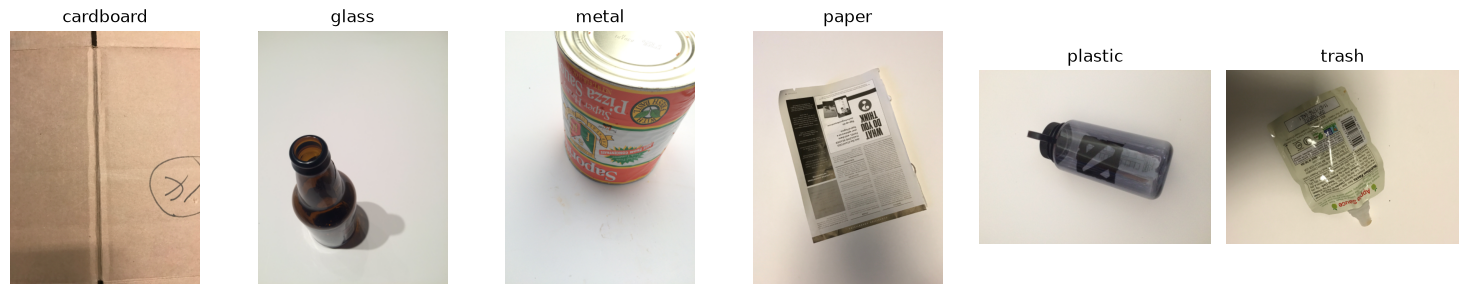

In [3]:
fig, axes = plt.subplots(1, len(class_names), figsize=(15, 3))
for ax, name in zip(axes, class_names):
    path = images.loc[images["Class"] == name, "Path"].iloc[0]
    with Image.open(path) as image:
        image.draft("RGB", (256, 256))
        image = ImageOps.exif_transpose(image).convert("RGB")
        ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Read raw color pixels
Resize each color image to 32 by 32 and flatten its three channels into **3,072 values**: 32 ? 32 ? 3. Divide by 255 to put values between 0 and 1. The same raw pixel features feed both models.

These are individual pixel intensities, rather than HSV histograms, RGB means or standard deviations. No HOG or LBP descriptors are used. A cache avoids repeatedly reading the high-resolution originals.


In [4]:
def read_pixels(path):
    with Image.open(path) as image:
        image.draft("RGB", (256, 256))
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = image.resize((32, 32))
        pixels = np.asarray(image, dtype=float).ravel() / 255.0
    return pixels

cache_path = OUTPUT_DIR / "color_pixels_v4.npz"
file_names = images["Path"].to_numpy(dtype=str)
file_sizes = np.array([Path(path).stat().st_size for path in file_names])
file_times = np.array([Path(path).stat().st_mtime_ns for path in file_names])
use_cache = False
if cache_path.exists():
    with np.load(cache_path) as cache:
        use_cache = (np.array_equal(cache["paths"], file_names)
                     and np.array_equal(cache["sizes"], file_sizes)
                     and np.array_equal(cache["times"], file_times))
        if use_cache:
            pixel_features = cache["pixels"]

if not use_cache:
    pixel_rows = []
    for index, path in enumerate(file_names):
        pixel_rows.append(read_pixels(path))
        if (index + 1) % 500 == 0:
            print("Images processed:", index + 1, flush=True)
    pixel_features = np.asarray(pixel_rows)
    np.savez_compressed(cache_path, paths=file_names, sizes=file_sizes,
                        times=file_times, pixels=pixel_features)

print("Pixel feature shape:", pixel_features.shape)
print("Delete the cache if you change read_pixels or the image size.")

Pixel feature shape: (2527, 3072)
Delete the cache if you change read_pixels or the image size.


## 3. Make the 80/20 split
The split is stratified to preserve class proportions and is shared by both models. The split manifest lets your friend evaluate other classifiers on the same images. This is a random image split; the dataset does not provide identifiers for physical objects.

In [5]:
train_indices, test_indices = train_test_split(
    np.arange(len(images)), test_size=0.20, random_state=SEED, stratify=y
)
y_train = y[train_indices]
y_test = y[test_indices]

manifest = images.copy()
manifest["Split"] = "Train"
manifest.loc[test_indices, "Split"] = "Test"
manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
print("Train images:", len(train_indices))
print("Test images:", len(test_indices))

Train images: 2021
Test images: 506


## 4. Set up cross-validation
An RBF SVM can learn nonlinear decision boundaries. C controls regularization and gamma controls how local the kernel influence is. We also try class weights to account for the smaller trash class.

For SVM + PCA, try retaining 90% and 95% of variance. Three-fold CV chooses the retention and SVM parameters using only training data. We fit scaling and PCA separately inside every fold. There are 36 configurations and 108 CV fits.

ParameterGrid enumerates combinations; explicit loops show the steps without a pipeline.

In [6]:
settings = {"SVM": None, "PCA 90%": 0.90, "PCA 95%": 0.95}
parameter_grid = list(ParameterGrid({
    "C": [1, 10, 100],
    "gamma": ["scale", 0.01],
    "class_weight": [None, "balanced"]
}))
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
X_training = pixel_features[train_indices]

In [7]:
for name, retained_variance in settings.items():
    train_scores = np.zeros((3, len(parameter_grid)))
    valid_scores = np.zeros((3, len(parameter_grid)))

    for fold_number, (fit_rows, valid_rows) in enumerate(folds.split(X_training, y_train)):
        scaler = StandardScaler()
        fold_train = scaler.fit_transform(X_training[fit_rows])
        fold_valid = scaler.transform(X_training[valid_rows])

        if retained_variance is not None:
            reducer = PCA(n_components=retained_variance, svd_solver="full")
            fold_train = reducer.fit_transform(fold_train)
            fold_valid = reducer.transform(fold_valid)

        for parameter_number, parameters in enumerate(parameter_grid):
            model = SVC(kernel="rbf", cache_size=512, **parameters)
            model.fit(fold_train, y_train[fit_rows])
            train_scores[fold_number, parameter_number] = model.score(fold_train, y_train[fit_rows])
            valid_scores[fold_number, parameter_number] = model.score(fold_valid, y_train[valid_rows])
        print(name, "finished fold", fold_number + 1, flush=True)

    for parameter_number, parameters in enumerate(parameter_grid):
        cv_rows.append({
            "Setting": name, "C": parameters["C"], "gamma": parameters["gamma"],
            "class_weight": str(parameters["class_weight"]),
            "Train accuracy": train_scores[:, parameter_number].mean(),
            "CV accuracy": valid_scores[:, parameter_number].mean(),
            "CV std": valid_scores[:, parameter_number].std()
        })

cv_results = pd.DataFrame(cv_rows)
svm_rows = cv_results[cv_results["Setting"] == "SVM"]
pca_rows = cv_results[cv_results["Setting"] != "SVM"]
best_svm = svm_rows.loc[svm_rows["CV accuracy"].idxmax()]
best_pca = pca_rows.loc[pca_rows["CV accuracy"].idxmax()]
best_parameters = pd.DataFrame([best_svm, best_pca]).reset_index(drop=True)
best_parameters["Model"] = ["SVM", "SVM + PCA"]
selected_name = best_parameters.loc[best_parameters["CV accuracy"].idxmax(), "Model"]
display(best_parameters)
print("Model selected using CV:", selected_name)
cv_results.to_csv(OUTPUT_DIR / "all_cv_results.csv", index=False)
best_parameters.to_csv(OUTPUT_DIR / "best_parameters.csv", index=False)

SVM finished fold 1
SVM finished fold 2
SVM finished fold 3
PCA 90% finished fold 1
PCA 90% finished fold 2
PCA 90% finished fold 3
PCA 95% finished fold 1
PCA 95% finished fold 2
PCA 95% finished fold 3
Model selected using CV: SVM


,Setting,C,gamma,class_weight,Train accuracy,CV accuracy,CV std,Model
0,SVM,10,scale,balanced,0.991094,0.625932,0.006159,SVM
1,PCA 95%,10,scale,balanced,0.984415,0.621970,0.010404,SVM + PCA


## 5. Train the two final models
Refit using all training rows and each model's CV-selected parameters. Test images only use the scaler and PCA learned on train. PCA scores are not whitened or rescaled.

In [8]:
models = {}
train_inputs = {}
test_inputs = {}

for index, row in best_parameters.iterrows():
    name = row["Model"]
    scaler = StandardScaler()
    X_fit = scaler.fit_transform(pixel_features[train_indices])
    X_evaluate = scaler.transform(pixel_features[test_indices])

    retained_variance = settings[row["Setting"]]
    if retained_variance is not None:
        reducer = PCA(n_components=retained_variance, svd_solver="full")
        X_fit = reducer.fit_transform(X_fit)
        X_evaluate = reducer.transform(X_evaluate)
        print("PCA variance target:", retained_variance)
        print("PCA retained components:", reducer.n_components_)

    class_weight = None if row["class_weight"] == "None" else "balanced"
    model = SVC(kernel="rbf", C=float(row["C"]), gamma=row["gamma"],
                class_weight=class_weight, cache_size=512)
    model.fit(X_fit, y_train)
    models[name] = model
    train_inputs[name] = X_fit
    test_inputs[name] = X_evaluate

PCA variance target: 0.95
PCA retained components: 179


## 6. Evaluate both models
Macro precision, recall and F1 give each class equal weight. Weighted F1 accounts for class sizes. ROC-AUC treats each class as positive versus all others; we average the six class AUCs. SVM decision scores provide the rankings, so probability estimation is unnecessary.

The preferred model was already selected using CV. Test results describe both predeclared alternatives and do not change that selection.

In [9]:
metric_rows = []
all_predictions = {}
all_scores = {}
classes = np.arange(len(class_names))

for name, model in models.items():
    prediction = model.predict(test_inputs[name])
    scores = model.decision_function(test_inputs[name])
    class_aucs = []
    for label in classes:
        fpr, tpr, thresholds = roc_curve(y_test == label, scores[:, label])
        class_aucs.append(auc(fpr, tpr))

    metric_rows.append({
        "Model": name,
        "Train accuracy": model.score(train_inputs[name], y_train),
        "Test accuracy": accuracy_score(y_test, prediction),
        "Macro precision": precision_score(y_test, prediction, average="macro", zero_division=0),
        "Macro recall": recall_score(y_test, prediction, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, prediction, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, prediction, average="weighted", zero_division=0),
        "Macro OvR AUC": np.mean(class_aucs)
    })
    all_predictions[name] = prediction
    all_scores[name] = scores

comparison = pd.DataFrame(metric_rows)
display(comparison)
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Preferred configuration (selected by CV):", selected_name)
print(classification_report(y_test, all_predictions[selected_name], target_names=class_names, zero_division=0))

prediction_table = images.iloc[test_indices].copy()
for name in models:
    prediction_table[name] = all_predictions[name]
prediction_table.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

Preferred configuration (selected by CV): SVM
              precision    recall  f1-score   support

   cardboard       0.69      0.72      0.70        81
       glass       0.53      0.48      0.50       100
       metal       0.51      0.59      0.55        82
       paper       0.68      0.69      0.69       119
     plastic       0.62      0.65      0.63        97
       trash       0.73      0.41      0.52        27

    accuracy                           0.61       506
   macro avg       0.63      0.59      0.60       506
weighted avg       0.62      0.61      0.61       506



,Model,Train accuracy,Test accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Macro OvR AUC
0,SVM,0.987135,0.612648,0.627150,0.587897,0.599045,0.610971,0.863869
1,SVM + PCA,0.980703,0.606719,0.624877,0.587636,0.599138,0.606828,0.865984


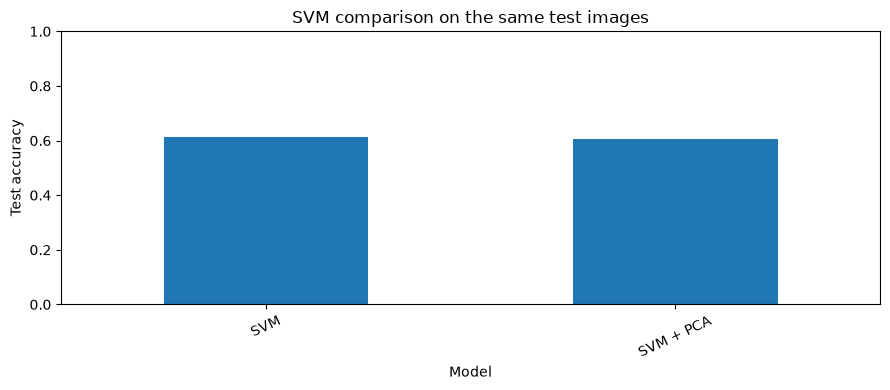

In [10]:
comparison.plot(x="Model", y="Test accuracy", kind="bar", legend=False, rot=25, figsize=(9, 4))
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("SVM comparison on the same test images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "accuracy_comparison.png", dpi=150)
plt.show()

## 7. Confusion matrices
Rows are actual classes and columns are predicted classes. Check the trash class as well as the overall accuracy.

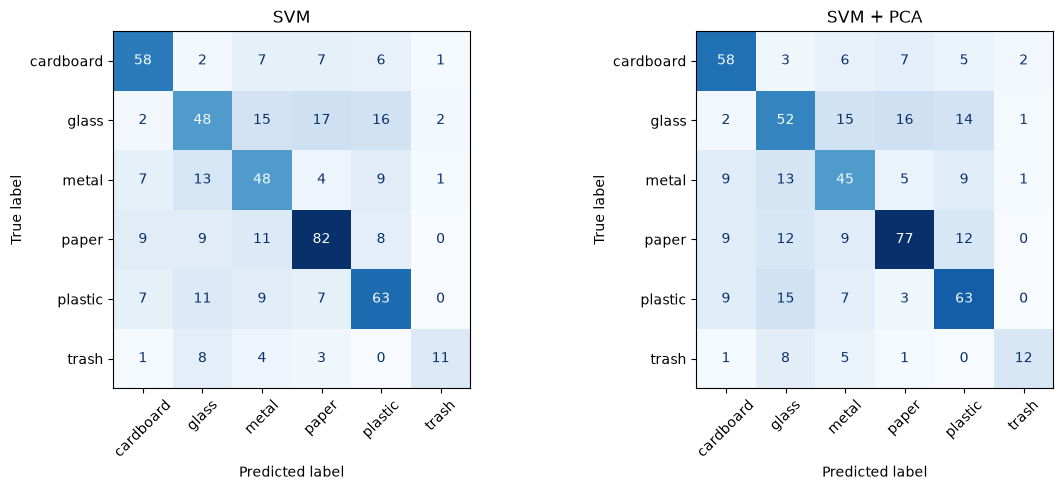

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, prediction) in zip(axes, all_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=class_names,
                                           cmap="Blues", ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## 8. ROC curves
Show one-vs-rest curves for the CV-selected model and macro-average curves for the two alternatives. AUC values are averaged over classes. Ranking SVM against KNN and Decision Tree also requires those classifiers' results on the same test images.

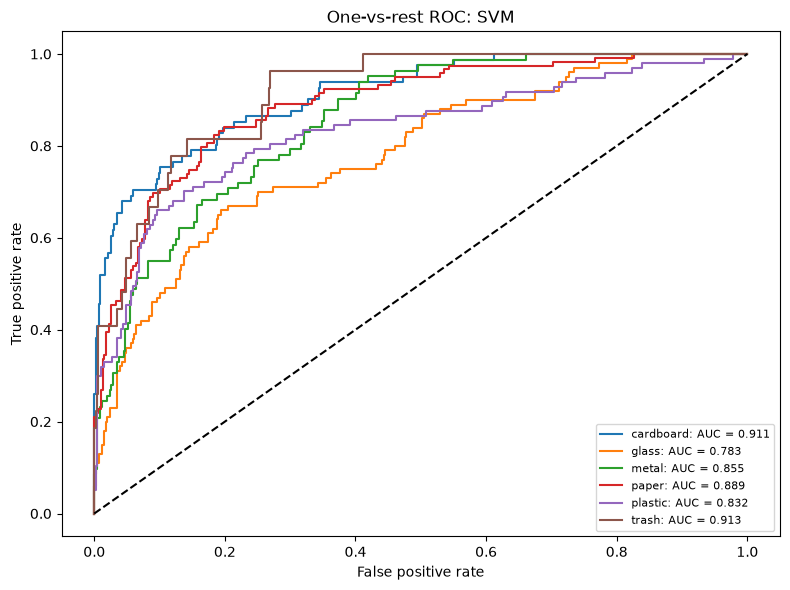

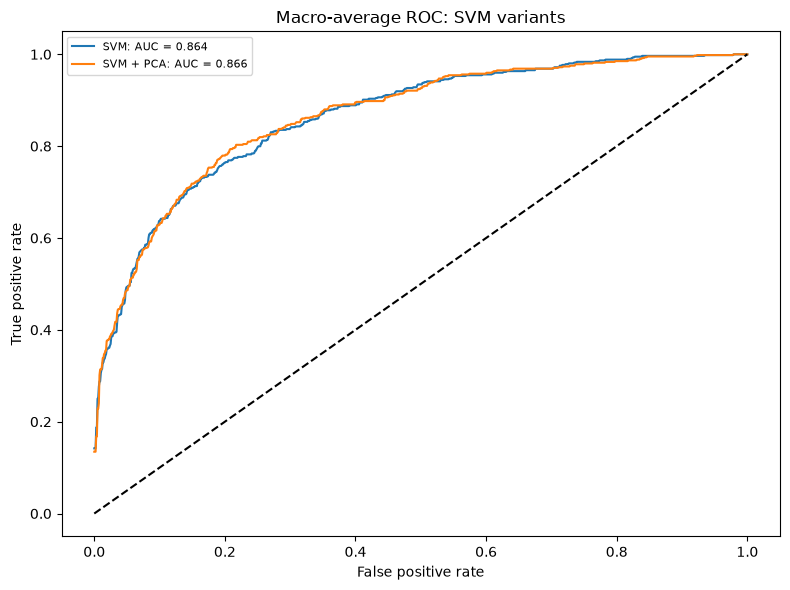

In [12]:
plt.figure(figsize=(8, 6))
selected_scores = all_scores[selected_name]
roc_rows = []
for label in classes:
    fpr, tpr, thresholds = roc_curve(y_test == label, selected_scores[:, label])
    plt.plot(fpr, tpr, label=f"{class_names[label]}: AUC = {auc(fpr, tpr):.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"One-vs-rest ROC: {selected_name}")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "selected_model_roc.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 6))
fpr_grid = np.linspace(0, 1, 1000)
for name, scores in all_scores.items():
    curves = []
    for label in classes:
        fpr, tpr, thresholds = roc_curve(y_test == label, scores[:, label])
        curves.append(np.interp(fpr_grid, fpr, tpr))
        for x_value, y_value in zip(fpr, tpr):
            roc_rows.append([name, class_names[label], x_value, y_value])
    mean_auc = comparison.loc[comparison["Model"] == name, "Macro OvR AUC"].iloc[0]
    plt.plot(fpr_grid, np.mean(curves, axis=0), label=f"{name}: AUC = {mean_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Macro-average ROC: SVM variants")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_roc_comparison.png", dpi=150)
plt.show()
pd.DataFrame(roc_rows, columns=["Model", "Class", "FPR", "TPR"]).to_csv(OUTPUT_DIR / "roc_points.csv", index=False)

## 9. Overfitting and model complexity
Plot training and CV accuracy versus C, holding the selected representation and class weights fixed. A large training/validation gap suggests overfitting. Larger C weakens regularization, and a large gamma can produce very local decision boundaries. PCA may reduce noise, but it can also discard information useful for classification.

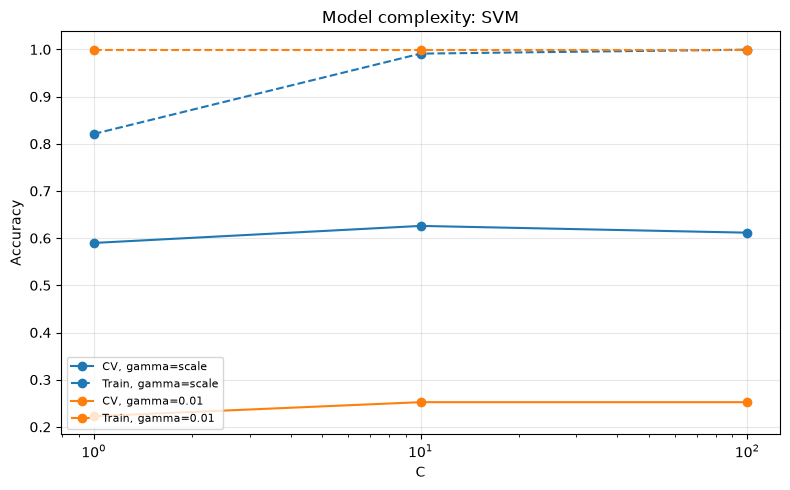

In [13]:
selected_row = best_parameters.loc[best_parameters["Model"] == selected_name].iloc[0]
selected_weight = selected_row["class_weight"]
subset = cv_results[(cv_results["Setting"] == selected_row["Setting"])
                    & (cv_results["class_weight"] == selected_weight)]
plt.figure(figsize=(8, 5))
for gamma in ["scale", 0.01]:
    part = subset[subset["gamma"] == gamma].sort_values("C")
    line, = plt.semilogx(part["C"], part["CV accuracy"], "o-", label=f"CV, gamma={gamma}")
    plt.semilogx(part["C"], part["Train accuracy"], "o--", color=line.get_color(),
                 label=f"Train, gamma={gamma}")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.title(f"Model complexity: {selected_name}")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_complexity.png", dpi=150)
plt.show()

## 10. Read the results
Both models use the same raw color pixels and the same test images. Compare accuracy, macro metrics, confusion matrices and ROC-AUC. Use training CV to explain the chosen C, gamma, class weights and PCA retention; do not assume PCA must improve performance.

The saved split can be shared with the other assignment classifiers. No hand-crafted image descriptors are used.

Documentation: [SVM](https://scikit-learn.org/stable/modules/svm.html), [avoiding preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html).


### Results from this run
| Model | Test accuracy | Macro F1 | Macro OvR AUC |
|---|---:|---:|---:|
| SVM | 61.26% | 0.599 | 0.864 |
| SVM + PCA | 60.67% | 0.599 | 0.866 |

Both models selected **C = 10**, **gamma = scale**, and **balanced class weights**. PCA selected **95% retained variance**, giving **179 components** instead of the 3,072 original color-pixel values.

Training CV preferred **SVM**, with mean CV accuracy **62.59%**, compared with **62.20%** for SVM + PCA. PCA reduced dimensionality but did not improve accuracy on this split. Its observed ROC-AUC was slightly higher, illustrating that accuracy and AUC measure different aspects of performance.

Training accuracies of **98.71%** and **98.07%** are substantially higher than CV/test accuracy, showing overfitting. Both models retain the original image colors through their raw input channels; neither uses hand-crafted descriptors.